# Praktikum 1 - K-Means Clustering (Dataset Iris)

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 04:** Klasterisasi

### Tujuan Praktikum:
1. Memahami konsep algoritma *unsupervised learning* K-Means.
2. Membangun model K-Means clustering menggunakan Scikit-Learn pada dataset Iris.
3. Memvisualisasikan sebaran data, klaster, dan posisi centroid.
4. Menentukan nilai $k$ optimal menggunakan **Metode Elbow** (Inertia / SSE).

## Langkah 1 - Load Data Iris

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

data_path = r'..\Dataset\Iris.csv'

df = pd.read_csv(data_path)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Langkah 2 - Seleksi Fitur Numerik

In [2]:
# Menyeleksi fitur numerik (mengabaikan Id dan kolom label/species jika ada)
feat_cols = [c for c in df.columns if c.lower() not in ['id', 'species']]
X = df[feat_cols]
print('Fitur yang digunakan:', feat_cols)
X.head()

Fitur yang digunakan: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## Langkah 3 - Visualisasi Sebaran Data Asli (Sepal Length vs Sepal Width)

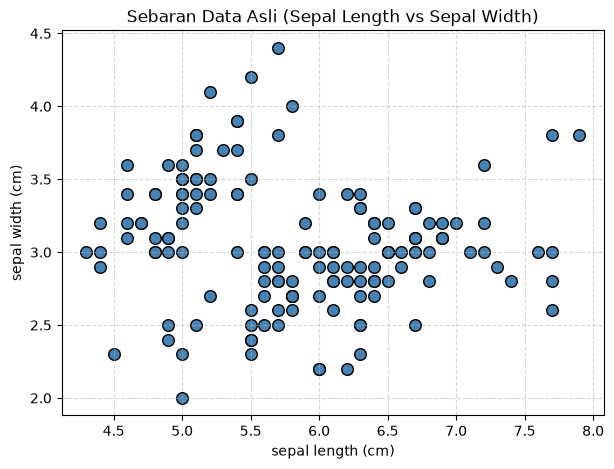

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=70, c='steelblue', edgecolors='k')
plt.title('Sebaran Data Asli (Sepal Length vs Sepal Width)')
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Langkah 4 - Pemodelan K-Means dengan k = 2 (Eksperimen Awal)

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


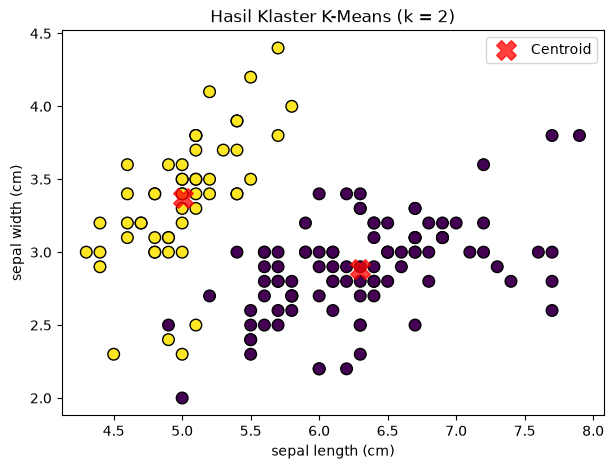

Nilai SSE (Inertia) untuk k=2: 152.3480


In [4]:
cl_kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto')
y_kmeans = cl_kmeans.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=70, c=y_kmeans, cmap='viridis', edgecolors='k')
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.75, marker='X', label='Centroid')
plt.title('Hasil Klaster K-Means (k = 2)')
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.legend()
plt.show()

print(f'Nilai SSE (Inertia) untuk k=2: {cl_kmeans.inertia_:.4f}')

## Langkah 5 - Implementasi Metode Elbow untuk Menentukan k Optimal
Mengevaluasi nilai Sum of Squared Errors (SSE) atau *inertia* untuk rentang $k = 1$ hingga $9$.

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


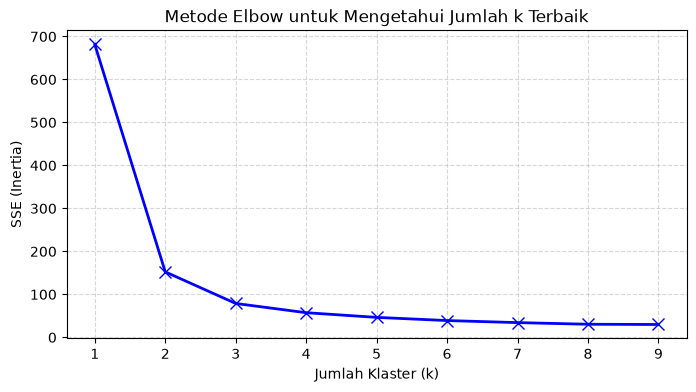

k = 1 -> SSE = 681.3706
k = 2 -> SSE = 152.3480
k = 3 -> SSE = 78.8557
k = 4 -> SSE = 57.3509
k = 5 -> SSE = 46.4722
k = 6 -> SSE = 39.0660
k = 7 -> SSE = 34.3058
k = 8 -> SSE = 30.4762
k = 9 -> SSE = 29.9062


In [5]:
sse = []
K = range(1, 10)
for k in K:
    model = KMeans(n_clusters=k, random_state=42, n_init='auto')
    model.fit(X)
    sse.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-', linewidth=2, markersize=8)
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('SSE (Inertia)')
plt.title('Metode Elbow untuk Mengetahui Jumlah k Terbaik')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

for idx, val in enumerate(sse, start=1):
    print(f'k = {idx} -> SSE = {val:.4f}')

## Langkah 6 - Pemodelan K-Means dengan k Optimal (k = 3)
Berdasarkan titik 'siku' (elbow) pada grafik, penurunan SSE mulai melandai secara signifikan setelah $k = 3$.

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


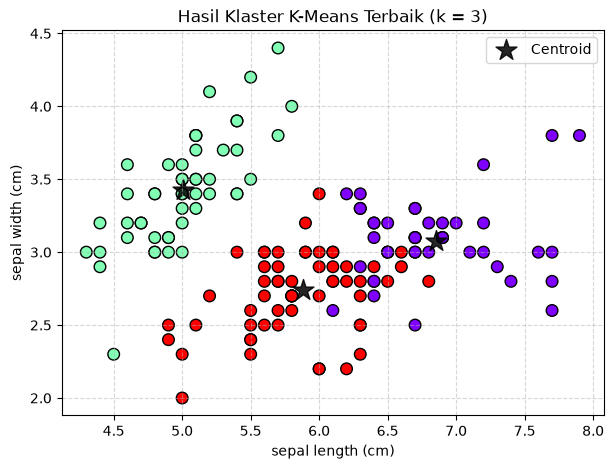

In [6]:
cl_kmeans3 = KMeans(n_clusters=3, random_state=42, n_init='auto')
y_kmeans3 = cl_kmeans3.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=70, c=y_kmeans3, cmap='rainbow', edgecolors='k')
centers3 = cl_kmeans3.cluster_centers_
plt.scatter(centers3[:, 0], centers3[:, 1], c='black', s=250, alpha=0.85, marker='*', label='Centroid')
plt.title('Hasil Klaster K-Means Terbaik (k = 3)')
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()